# Reduced attitude control

A quadrotor's thrust direction determines the direction of its propulsive force. We consider two controllers: one aligns the thrust direction with the vertical, and the other makes it rotate around a prescribed cone. This example tests whether a learned model preserves these known behaviors when the topological computation is performed in one dimension. Training trajectories start with zero angular-velocity tracking error. The learned model predicts thrust direction, not the full quadrotor state.

## Setup

The saved outputs can be read without running Python. To reproduce them, follow the [installation instructions](README.md#install), select that environment's kernel, and run the cells in order from the repository root. Python 3.13, Graphviz (`dot`), and Poppler (`pdftoppm`) are required.

The default `MODE = "replay"` loads the validation-selected fit for each controller and recomputes its results without retraining. `MODE = "train"` instead retrains those selected seeds. `OUT = None` creates a fresh directory under `outputs/notebooks/` for numerical results and PDF/SVG figures.

The calls below use `Notebook` in [`morsegraphs/attitude_control.py`](morsegraphs/attitude_control.py). That module contains the controller (`field`, `rhs`), learned maps (`AttitudeModel`), and loss (`_pieces`). The shared modules [`grids.py`](morsegraphs/grids.py), [`regions.py`](morsegraphs/regions.py), and [`homology.py`](morsegraphs/homology.py) compute the cell graphs, attracting regions, and reconstructed indices. Model and data settings are recorded in [`config.json`](data/ex3_attitude_control/config.json).


In [1]:
MODE = "replay"  # "replay" or "train"
OUT = None       # None, or a new folder for the results and figures
{"MODE": MODE, "OUT": OUT}

{'MODE': 'replay', 'OUT': None}

The networks run in float32 on the CPU, as when they were fitted; CMGDB, the reference maps and the tolerances use binary64. The device is chosen before JAX starts.

In [2]:
from morsegraphs import device
device.configure("float32")

{'device': 'cpu',
 'precision': 'float32',
 'remarks': ["Apple GPU unavailable for EMLP: jax-metal lacks float64 and eigh, and EMLP's PyTorch layers keep their projections on the CPU"]}

In [3]:
from morsegraphs import attitude_control as ac
run = ac.Notebook(MODE, OUT)
run

setting,value
mode,replay
data,data/ex3_attitude_control
output folder,outputs/notebooks/ex3_attitude_control-replay-20261114-013128
selected fits,"nominal-seed0, coning-seed0 (lowest validation objective, chosen before any CMGDB computation)"
networks,"JAX 0.4.38 on cpu, float32"
CMGDB,"1.5.3+fork.7, binary64, coefficients in F_5"


## Controlled motion and physical quotient

The rigid-body state is \((p,v,R,\Omega)\in\mathbb R^3\times\mathbb R^3\times\mathrm{SO}(3)\times\mathbb R^3\). Position and velocity are \(p,v\), orientation is \(R\), and body angular velocity is \(\Omega\). The thrust direction is \(q=Re_3\in S^2\), where \(e_3=(0,0,1)\). Write \(z=q\cdot e_3\) and \(w=R\Omega\).

For a gain \(a:[-1,1]\to\mathbb R\), prescribe
$$V_a(q)=a(z)(e_3-zq)+\omega e_3\times q,\qquad \omega=\pi/\log2.$$
The first term changes the tilt, while the second rotates the thrust direction about the vertical. Both are tangent to the sphere. Define \(w_d(q)=q\times V_a(q)\) and the rate error \(\eta=w-w_d(q)\). With inertia matrix \(J\), the control moment is
$$M=\Omega\times J\Omega+JR^\top\bigl(Dw_d(q)[w\times q]-2\eta\bigr).$$
Here \(Dw_d(q)[h]\) is the directional derivative in direction \(h\). For tangent \(h\) it is
$$Dw_d(q)[h]=a'(z)h_3(q\times e_3)+a(z)(h\times e_3)-\omega(h_3q+zh).$$
Substitution into the rigid-body equations gives
$$\dot q=V_a(q)+\eta\times q,\qquad \dot\eta=-2\eta.$$
Thus \(\eta=0\) is invariant. All training trajectories start there, so the thrust direction evolves autonomously under a flow \(F_t:S^2\to S^2\). For mass \(\mu\) and gravitational acceleration \(g\), the thrust magnitude is fixed at \(\mu g\), giving \(\dot v=g(q-e_3)\). This controller regulates the thrust direction but not position, so a coning thrust direction need not produce a periodic flight path.


The table checks the closed-loop identities and integrator on sampled states. For coning, it also checks the period \(2\log 2\) and the transverse Floquet multipliers \(\exp(-15\log 2/8)\) and \(1/16\) three times in \((q,\eta)\). These multipliers describe contraction toward the periodic orbit.


In [4]:
run.system()

check,nominal,coning,bound or exact value
"max |η' + 2η|, closed-loop identity",2.44249e-14,1.68754e-14,< 1e-11
max |q' − V_a(q) − η × q|,4.44089e-15,4.44089e-15,< 1e-11
"equivariance of q, η, q' and M, max error",4.21885e-15,4.55191e-15,< 1e-11
"RK4 with steps 0.001 and 0.002, max difference over 1 s",4.39719e-10,3.69877e-10,< 2e-7
"observed axis against the flow of V_a on η = 0, max error over 1 s",8.29464e-11,8.90189e-11,< 2e-7
"|η(t) − exp(−2t) η(0)| for |η(0)| ≤ 6 over 20 s, max",9.96767e-10,7.32324e-10,< 2e-7
period of the coning orbit C,,1.38629,2 log 2 = 1.38629
"Floquet multipliers of C in (q, η)",,"0.0625, 0.0625, 0.0625, 0.272627, 1","1, exp(−15 log 2/8) = 0.272627, 1/16 three times"


## The physical quotient


For a rotation \(Q\in\mathrm{SO}(2)\) about \(e_3\), the state action is \((p,v,R,\Omega)\mapsto(Qp,Qv,QR,\Omega)\) and \(q\mapsto Qq\). The height projection \(\pi:S^2\to[-1,1]\), \(\pi(q)=q_3\), identifies directions that differ only by such a rotation. On \(\eta=0\),
$$\dot z=e_3\cdot V_a(q)=a(z)(1-z^2).$$
The quotient flow \(h_t:[-1,1]\to[-1,1]\) satisfies \(\pi\circ F_t=h_t\circ\pi\). Away from the poles the azimuth satisfies \(\dot\varphi=\omega\).

| Controller | Gain \(a(z)\) | Attracting behavior | Exceptional initial directions |
|---|---|---|---|
| Nominal | \(1\) | Upright direction \(q=e_3\) | The downward pole remains fixed |
| Coning | \(1/4-z\) | Circle \(q_3=1/4\), with period \(2\log2\) | Both poles remain fixed |

For example, \((\sqrt3/2,0,1/2)\) and \((0,\sqrt3/2,1/2)\) represent the same quotient state. At this height the nominal controller gives \(\dot z=3/4\), while coning gives \(\dot z=(1/4-1/2)(1-1/4)=-3/16\). The first moves toward upright alignment, and the second moves toward the prescribed cone. An equilibrium of the height equation can therefore represent a rotating circle rather than a stationary thrust direction.
The computation uses the time-one height map \(h_1\). The table compares its derivative at each fixed height with a numerical difference quotient. A derivative of magnitude below one indicates attraction in height.


In [5]:
run.reference_map()

gain,fixed set,height z*,h₁(z*),h₁'(z*) = exp(g'(z*)),difference quotient,
nominal,S,-1,-1,7.38906,7.38906,repelling
nominal,N,1,1,0.135335,0.135335,attracting
coning,S,-1,-1,12.1825,12.1825,repelling
coning,C,0.25,0.25,0.391606,0.391606,attracting
coning,N,1,1,4.48169,4.48169,repelling


## The reference Morse graph

Partition \([-1,1]\) into 128 cells. For each cell, sample the time-one height map at 257 points, take the minimum and maximum images, expand that interval by \(2\times10^{-6}\), and clip it to \([-1,1]\). A directed edge joins the source cell to every cell meeting its image interval. These sampled hulls are not validated enclosures.

A Morse component consists of recurrent, mutually reachable cells. CMGDB represents each component by a node and records reachability between nodes. A minimal node has no outgoing path to another node. The resulting graph describes the finite cell relation. Its arrows alone do not prove connecting trajectories of the physical system.

CMGDB also computes Conley indices over \(\mathbb F_5\), the field of integers modulo five. For an index pair \((N,L)\), the relevant groups are \(H_k(N,L;\mathbb F_5)\), the homology of an isolating neighborhood relative to its exit set. The displayed tuples list the surviving index-map polynomials in degrees 0 and 1. Here `x-1` denotes one class with identity action, while `0` denotes a trivial Conley-index entry. The polynomial variable `x` is not a state coordinate.


In [6]:
run.reference_graphs()

gain,Morse set,cells,"cells cover, in z",Conley index (CMGDB),edges to
nominal,S,1,"[-1, -0.984375]","(0, 0)",N
nominal,N,1,"[0.984375, 1]","(x-1, 0)",
coning,S,1,"[-1, -0.984375]","(0, 0)",C
coning,C,2,"[0.234375, 0.265625]","(x-1, 0)",
coning,N,1,"[0.984375, 1]","(0, 0)",C


## Trajectory data

Each controller has 8,192 training, 2,048 validation, and 4,096 test trajectories, with 33 observations at 0.1-second spacing. The splits contain independent trajectories. Initial conditions satisfy \(\eta=0\), with independent translation and heading. A quarter start at heights within \(10^{-7}\) to \(10^{-2}\) of a pole.

The observation is \(o=(p,v,Re_1,Re_2,Re_3,\Omega)\in\mathcal O\subset\mathbb R^{18}\). The simulator uses fourth-order Runge–Kutta with step 0.002 seconds and normalizes the orientation quaternion at each step. The table checks the saved files against their metadata.


In [7]:
run.data_files()

gain,split,trajectories,observations each,generator seed,file SHA-256 (first 16),checksum matches
nominal,train,8192,33,2026111311,0605d9b527cf9e0e,yes
nominal,validation,2048,33,2026111312,5ffea67d149ac624,yes
nominal,test,4096,33,2026111323,5d72f2ebe100334a,yes
coning,train,8192,33,2026111311,4ece231f0ee49168,yes
coning,validation,2048,33,2026111312,816e5300fb27b72d,yes
coning,test,4096,33,2026111323,80202008e63764f7,yes


## Encoder, time-step map, and decoder

The encoder maps observations to a latent sphere equivariantly: rotating the plant about the vertical rotates the latent vector by the same angle. Taking its height then reduces the dynamics to an interval. 

Let \(o=(p,v,Re_1,Re_2,Re_3,\Omega)\in\mathcal O\subset\mathbb R^{18}\) be the observation. The target \(q(o)=Re_3\) is already present in entries `12:15`. For rotation \(Q\) about the vertical, the first five vector blocks rotate by \(Q\) and body angular velocity stays fixed. The EMLP representation enforces this action. An EMLP is a neural network whose layers commute with the specified group action.

The encoder \(E:\mathcal O\to Z=S^2\) and decoder \(D:Z\to S^2\) have raw equivariant networks \(N_E,N_D\):
$$E(o)=\nu\bigl(N_E(S^{-1}(o-\mu_o))\bigr),\qquad D(\ell)=\nu(N_D(\ell)),\qquad
\nu(y)=\frac{y}{\max(\|y\|,10^{-12})}.$$
The saved mean \(\mu_o\) and diagonal scale \(S\) come from training observations. For each of the first five vector blocks, only its vertical mean is removed and one RMS scale is shared across the block. Body-rate entries use componentwise means and standard deviations. The thrust-direction block is overridden to mean zero and scale one. These operations respect the group action. Unit output requires the raw norm to be at least the numerical floor. The held-out checks support the sphere interpretation, but do not prove global nonvanishing.

Here \(\ell=(\ell_1,\ell_2,\zeta)\in Z\) denotes a latent vector. The learned map \(f:Z\to Z\) advances **0.1 seconds**. Its scalar network outputs \(B(\zeta),A(\zeta)\), from which we define
$$b(\zeta)=0.5\tanh B(\zeta),\qquad \alpha(\zeta)=\tanh A(\zeta).$$
Writing \(d(\zeta)=\cosh b(\zeta)+\zeta\sinh b(\zeta)\), the full map is
$$f(\ell)=\frac{1}{d(\zeta)}\begin{pmatrix}
\cos\alpha(\zeta)\,\ell_1-\sin\alpha(\zeta)\,\ell_2\\
\sin\alpha(\zeta)\,\ell_1+\cos\alpha(\zeta)\,\ell_2\\
\zeta\cosh b(\zeta)+\sinh b(\zeta)
\end{pmatrix}.$$
The denominator is positive on \([-1,1]\), and this formula preserves the sphere and fixes both poles. Its height map is
$$\bar f(\zeta)=\frac{\zeta\cosh b(\zeta)+\sinh b(\zeta)}{d(\zeta)}.$$
Interior fixed heights satisfy \(b(\zeta)=0\). The angle \(\alpha(\zeta)\) determines the rotation along each such circle. The desired prediction is \(D(f^j(E(o_0)))\approx q(o_j)\) for observations \(0.1j\) seconds apart.

### Learned interval coordinate

The height projection is \(\pi_Z(\ell)=\zeta\). A learned increasing piecewise-linear homeomorphism \(\psi:[-1,1]\to[-1,1]\) gives \(u=\psi(\zeta)\). Its 33 equally spaced input knots are \(\kappa_i=-1+i/16\), \(i=0,\ldots,32\). A scalar network \(c\) defines positive increments
$$\delta_i=\exp\!\left(0.35\tanh c\left(\frac{\kappa_i+\kappa_{i+1}}2\right)\right),\qquad
\psi(\kappa_j)=-1+2\frac{\sum_{i<j}\delta_i}{\sum_{i=0}^{31}\delta_i}.$$
Linear interpolation defines \(\psi\) between knots. Positive increments guarantee an increasing inverse. A separate interval decoder \(\rho:[-1,1]\to[-1,1]\) uses the same construction with its own network. It is trained to recover latent height and is not set equal to \(\psi^{-1}\).

The interval encoder is \(\psi\circ\pi_Z\circ E\), and its time-step map is \(\psi\circ\bar f\circ\psi^{-1}\). Thus \(\pi_Z\circ f=\bar f\circ\pi_Z\) holds by construction. The topological computation uses \((\psi\circ\bar f\circ\psi^{-1})^{10}\), corresponding to one second. Thus the physical height \(z\), encoded height \(\zeta\), and interval coordinate \(u\) must be distinguished when comparing the learned and physical dynamics.

## Training objective

Let \(o_j\) be an observation at time \(t+0.1j\), with \(j\in\mathcal H=\{0,1,4,10\}\). Define \(q_j=q(o_j)\), \(\ell_j=E(o_j)\), \(\widehat\ell_j=f^j(E(o_0))\), \(\zeta_j=\pi_Z(\ell_j)\), and \(\widehat\zeta_j=\pi_Z(\widehat\ell_j)\). Predictions use \(\mathcal H_+=\{1,4,10\}\). For vector errors, squared norms below are divided by three to match the code's mean over coordinates. Every expectation is an empirical average over the batch and the indicated horizons.

| Term | Formula | Purpose |
|---|---|---|
| Reconstruction | \(L_{\rm rec}=\mathbb E\Vert D(\ell_0)-q_0\Vert ^2/3\) | Recover the initial thrust direction |
| Prediction | \(L_{\rm pred}=\mathbb E_{j\in\mathcal H_+}\Vert D(\widehat\ell_j)-q_j\Vert ^2/3\) | Predict future thrust directions |
| Encoder supervision | \(L_{\rm cal}=\mathbb E_{j\in\mathcal H}\Vert \ell_j-q_j\Vert ^2/3\) | Keep the latent vector close to the known thrust direction |
| Latent consistency | \(L_{\rm con}=\mathbb E_{j\in\mathcal H_+}\Vert \widehat\ell_j-\ell_j\Vert ^2/3\) | Match predicted and encoded latent states |
| Height reconstruction | \(L_{\rm hr}=\mathbb E_{j\in\mathcal H}(\rho(\psi(\zeta_j))-\zeta_j)^2\) | Decode the interval coordinate |
| Height prediction | \(L_{\rm hp}=\mathbb E_{j\in\mathcal H_+}(\rho(\psi(\widehat\zeta_j))-\zeta_j)^2\) | Predict latent height |
| Interval consistency | \(L_{\rm ic}=\mathbb E_{j\in\mathcal H_+}(\psi(\widehat\zeta_j)-\psi(\zeta_j))^2\) | Compare predictions in the learned interval coordinate |

The joint objective is
$$L=L_{\rm rec}+3L_{\rm pred}+2L_{\rm cal}+0.5(L_{\rm con}+L_{\rm hr}+L_{\rm hp})+0.1L_{\rm ic}.$$
The first 1,000 updates instead use \(L_{\rm rec}+4L_{\rm cal}+0.5L_{\rm hr}\). These definitions correspond to `_pieces` in `morsegraphs/attitude_control.py`. The known thrust direction supervises the encoder, so this experiment does not discover an unknown physical reduction.

## Saved fits and validation selection

The sphere networks have width 64 and two hidden layers. Scalar networks have width 24 and two hidden layers. Training uses batches of 256, 1,000 initial calibration updates, and the joint objective through update 6,000. AdamW uses weight decay \(10^{-6}\), gradient-norm clipping at 1, and a cosine learning rate from \(0.002\) to \(0.00005\).

Five seeds were fitted for each controller. Checkpoints and seeds were selected by the joint validation objective before any graph computation. The table retains all five results, so the variation across fits remains visible.


In [8]:
run.seeds()

gain,fit,rank,validation objective,test objective,one-second axis RMS (test),best step,
nominal,nominal-seed0,1,2.02913e-06,1.98303e-06,0.00100549,6000,selected
nominal,nominal-seed4,2,3.23482e-06,3.28029e-06,0.00106404,6000,
nominal,nominal-seed2,3,3.80302e-06,3.64327e-06,0.00124772,6000,
nominal,nominal-seed1,4,3.95735e-06,3.91036e-06,0.00143109,6000,
nominal,nominal-seed3,5,5.26517e-06,5.29802e-06,0.00133432,6000,
coning,coning-seed0,1,7.18928e-06,6.96636e-06,0.00183077,6000,selected
coning,coning-seed3,2,8.35951e-06,8.20601e-06,0.00151426,6000,
coning,coning-seed2,3,9.32044e-06,9.16698e-06,0.00173309,6000,
coning,coning-seed1,4,9.82513e-06,9.67018e-06,0.00206042,6000,
coning,coning-seed4,5,0.867251,0.868003,0.254183,6000,


Replay loads the selected checkpoints and verifies their file hashes. In train mode, the same cell fits the selected seeds and compares the resulting weights with the saved ones.


In [9]:
run.fits()

gain,fit,folder,weights SHA-256 (first 16),check
nominal,nominal-seed0,data/ex3_attitude_control/models/nominal-seed0,796adf953f3c85e7,file SHA-256 equals config.json: yes
coning,coning-seed0,data/ex3_attitude_control/models/coning-seed0,bd7f09f667f55578,file SHA-256 equals config.json: yes


## Held-out prediction errors

For test observations \(o_0,o_{10}\) one second apart, the thrust-direction error is
$$\sqrt{\mathbb E\|D(f^{10}(E(o_0)))-q(o_{10})\|^2/3}.$$
The average is over held-out trajectories initialized on \(\eta=0\). The same time-0.1 map is applied ten times without resetting to observations. This componentwise RMS error measures thrust-direction prediction, not angular distance or full-state error. The table also reports the objective and sampled checks of equivariance and sphere normalization.


In [10]:
run.errors()

quantity,nominal,coning,Section 5.3
"one-second axis RMS, componentwise (test trajectories)",0.00100549,0.00183077,below 0.002
validation objective,2.02913e-06,7.18928e-06,
test objective,1.98303e-06,6.96636e-06,
"axis prediction RMS at 1, 4 and 10 steps (test windows)",0.000498419,0.00103315,
"latent closure RMS at 1, 4 and 10 steps (test windows)",0.000643256,0.00127476,
fixed heights of fbar between the poles,,0.247074,
"sampled equivariance error of E and f, max",1.40404e-07,1.7894e-07,
"image hulls against 4,097 samples per cell, largest excess",0,0,≤ 0


## Learned Morse graphs and grouping

The interval encoder is \(\psi\circ\pi_Z\circ E\), where \(\pi_Z(\ell)=\zeta\) and \(u=\psi(\zeta)\). CMGDB analyzes the tenth iterate of \(\psi\circ\bar f\circ\psi^{-1}\), corresponding to one second, on the same 128-cell interval grid.

For coning, the known physical dynamics have two repelling poles and one attracting latitude. This motivates grouping the interior Morse components. Before merging, the code checks that there is exactly one minimal interior component, that the other interior components have trivial indices, and that no edge leaves the group. It also checks order convexity: every node on a path between group members must belong to the group. The merge includes connecting cells and recomputes the index on the resulting pair. A zero index alone is not grounds for discarding a component. Both the original and grouped graphs are retained.


In [11]:
run.learned_graphs()

gain,graph,Morse set,cells,"cells cover, in u",Conley index (CMGDB),edges to,Morse sets of the raw graph
nominal,raw,S,1,"[-1, -0.984375]","(0, 0)",N,
nominal,raw,N,1,"[0.984375, 1]","(x-1, 0)",,
nominal,merged,S,1,"[-1, -0.984375]","(0, 0)",N,S
nominal,merged,N,1,"[0.984375, 1]","(x-1, 0)",,N
coning,raw,S,1,"[-1, -0.984375]","(0, 0)",C,
coning,raw,C,1,"[0.234375, 0.25]","(x-1, 0)",,
coning,raw,A,1,"[0.25, 0.265625]","(0, 0)",C,
coning,raw,N,1,"[0.984375, 1]","(0, 0)",A,
coning,merged,S,1,"[-1, -0.984375]","(0, 0)",C,S
coning,merged,C,2,"[0.234375, 0.265625]","(x-1, 0)",,"C, A"


## Comparison with the reference

The physical and learned graphs must be compared in corresponding coordinates. The reference is therefore computed both in physical height \(z\) and after the change of coordinate \(u=\psi(z)\), using the same grid and grouping rule as the learned map.

For the selected coning fit, the reference and learned graphs in \(u\) each have an additional interior component, on opposite sides of the attracting component \(C\). Their grouped graphs agree, including the cells assigned to each node. The table checks these comparisons explicitly. Labels \(S\) and \(N\) denote the south and north poles, \(C\) the coning component, and \(A\) an additional interior component.


In [12]:
run.comparison()

gain,graph,Morse sets and indices,order,Morse sets between the poles,agrees with the learned graph of its kind
nominal,reference in z,"S (0, 0), N (x-1, 0)",S → N,,order yes; indices yes
nominal,"reference in ψ, raw","S (0, 0), N (x-1, 0)",S → N,,order yes; indices yes; cells yes
nominal,"reference in ψ, merged","S (0, 0), N (x-1, 0)",S → N,,order yes; indices yes; cells yes
nominal,"learned, raw","S (0, 0), N (x-1, 0)",S → N,,
nominal,"learned, merged","S (0, 0), N (x-1, 0)",S → N,,
coning,reference in z,"S (0, 0), C (x-1, 0), N (0, 0)","S → C, N → C","C [0.234375, 0.265625]",order yes; indices yes
coning,"reference in ψ, raw","S (0, 0), A (0, 0), C (x-1, 0), N (0, 0)","A → C, S → A, N → C","C [0.25, 0.265625], A [0.234375, 0.25]",order no; indices yes; cells no
coning,"reference in ψ, merged","S (0, 0), C (x-1, 0), N (0, 0)","S → C, N → C","C [0.234375, 0.265625]",order yes; indices yes; cells yes
coning,"learned, raw","S (0, 0), C (x-1, 0), A (0, 0), N (0, 0)","S → C, A → C, N → A","C [0.234375, 0.25], A [0.25, 0.265625]",
coning,"learned, merged","S (0, 0), C (x-1, 0), N (0, 0)","S → C, N → C","C [0.234375, 0.265625]",


## Attracting regions, tolerances, and residuals

For a minimal Morse component \(\mathcal M\), collect cells from which no path of the finite graph leaves the domain or reaches another Morse component. Write \(N\) for their union. Its tolerance measures the distance from the sampled cell-image hulls to the complement of \(N\).

To compare this tolerance with prediction error, use one-second observation pairs \((o,o')\) whose initial encoded interval coordinate lies in \(N\). The residual compares \(\bar f^{10}(\pi_ZE(o))\) with \(\pi_ZE(o')\). Both tolerance and residual use the quotient of the chordal metric on the latent sphere, after undoing \(\psi\). For heights \(s,t\), this distance is
$$d(s,t)=\sqrt{(s-t)^2+\bigl(\sqrt{1-s^2}-\sqrt{1-t^2}\bigr)^2}.$$
It is the minimum Euclidean distance between the corresponding latitude circles.

The table includes the coning region before and after grouping. Before grouping, cells that can reach the additional component are excluded. The grouped region includes them. Residual maxima and tolerances are sampled estimates, so their comparison is not a uniform guarantee for the physical system.


In [13]:
run.regions()

gain,minimal Morse set (Morse sets of the raw graph),graph,cells of 𝒜,N in u,samples in E⁻¹(N),tolerance,max residual,residual < tolerance
nominal,N (N),merged,127,"[-0.984375, 1]",87450,0.294831,0.014871,yes
coning,"C (C, A)",merged,126,"[-0.984375, 0.984375]",76823,0.172168,0.0148922,yes
coning,C (C),raw,79,"[-0.984375, 0.25]",48090,0.00180907,0.0148922,no


## Reconstructed indices on the sphere

An interior quotient height represents a circle, while an endpoint represents a single pole. Recovering a sphere index therefore requires more than reusing the interval index.

The reconstruction theorem in the paper's appendix combines the quotient index on \((N/G,L/G)\) with the index relative to \(K/G\), where \(K=L\cup(N\cap P)\) and \(P/G=\{-1,1\}\) consists of the fixed poles. Here the orbit dimension is one and the degree on the circle is one. [`reconstructed_index`](morsegraphs/homology.py) computes these two index maps from the cell relation and combines them to obtain the lifted index.

The table compares these computations with the physical thrust-axis indices derived from explicit index pairs in the paper. A repelling pole has \(H_2(N,L;\mathbb F_5)\cong\mathbb F_5\), the upright sink has \(H_0(N,L;\mathbb F_5)\cong\mathbb F_5\), and the attracting coning circle has nonzero groups in degrees 0 and 1. The corresponding nonzero index maps are identities. For the learned graph, the reconstruction concerns the lifted cell model. Agreement with the physical indices is a numerical comparison, not a certified identification of physical invariant sets.


In [14]:
run.indices()

gain,graph,Morse set,"index on [-1, 1] (CMGDB)","index on [-1, 1] (homology)",cells of N_P/G,index in S² (reconstructed),index in S² (proved),agree
nominal,reference in z,S,"(0, 0)","(0, 0)",1,"(0, 0, x-1)","(0, 0, x-1)",yes
nominal,reference in z,N,"(x-1, 0)","(x-1, 0)",1,"(x-1, 0, 0)","(x-1, 0, 0)",yes
nominal,"reference in ψ, merged",S,"(0, 0)","(0, 0)",1,"(0, 0, x-1)","(0, 0, x-1)",yes
nominal,"reference in ψ, merged",N,"(x-1, 0)","(x-1, 0)",1,"(x-1, 0, 0)","(x-1, 0, 0)",yes
nominal,"learned, merged",S,"(0, 0)","(0, 0)",1,"(0, 0, x-1)","(0, 0, x-1)",yes
nominal,"learned, merged",N,"(x-1, 0)","(x-1, 0)",1,"(x-1, 0, 0)","(x-1, 0, 0)",yes
coning,reference in z,S,"(0, 0)","(0, 0)",1,"(0, 0, x-1)","(0, 0, x-1)",yes
coning,reference in z,C,"(x-1, 0)","(x-1, 0)",0,"(x-1, x-1, 0)","(x-1, x-1, 0)",yes
coning,reference in z,N,"(0, 0)","(0, 0)",1,"(0, 0, x-1)","(0, 0, x-1)",yes
coning,"reference in ψ, merged",S,"(0, 0)","(0, 0)",1,"(0, 0, x-1)","(0, 0, x-1)",yes


## Nominal control

(a) The grouped learned interval graph, with its computed indices. (b) The preimages of its cells under \(\psi\circ\pi_Z\) on the latent sphere, with the Morse components in solid colors and the attracting region in a lighter tint. (c) The same graph with reconstructed sphere indices.

The attractor is green. The repelling south pole is vermilion. The graph runs from \(S\) to the upright sink \(N\). Panel (b) uses latent coordinates, not inverse images under the full-state encoder. The cell saves PDF and SVG panels under `OUT/figures/attitude/nominal/`.


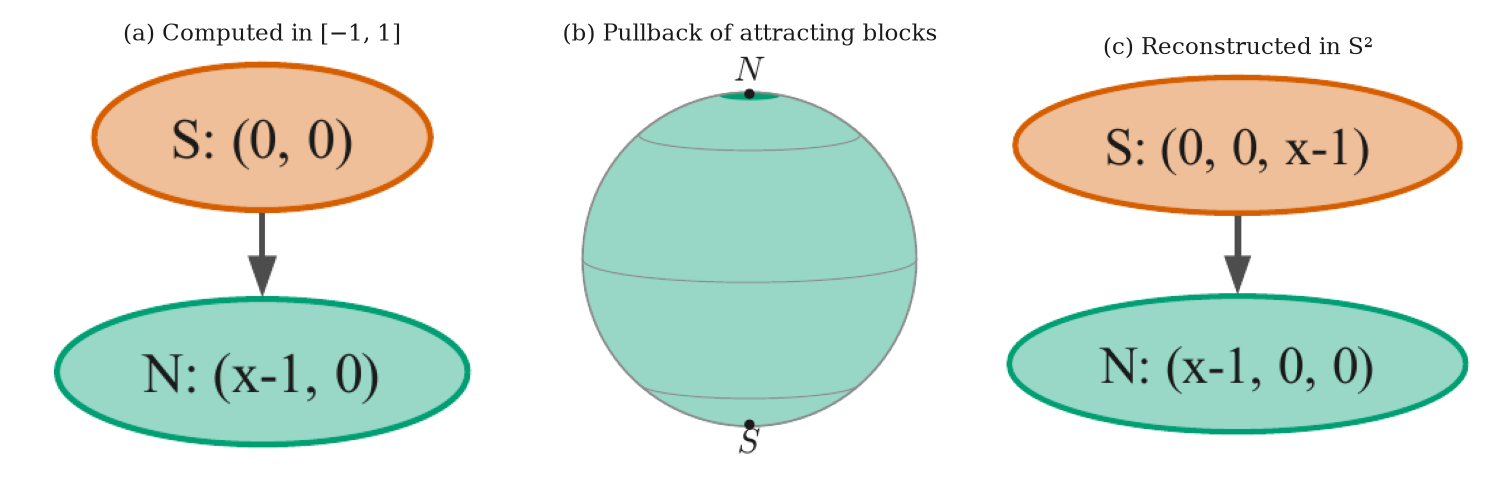

In [15]:
run.figure_nominal()

## Coning control

The panels have the same meaning as above. Both poles lead to the attracting coning component. The repelling north pole is orange, and the attracting component is green. Panel (b) shows the grouped region used in the tolerance comparison. The panels are saved under `OUT/figures/attitude/coning/`.


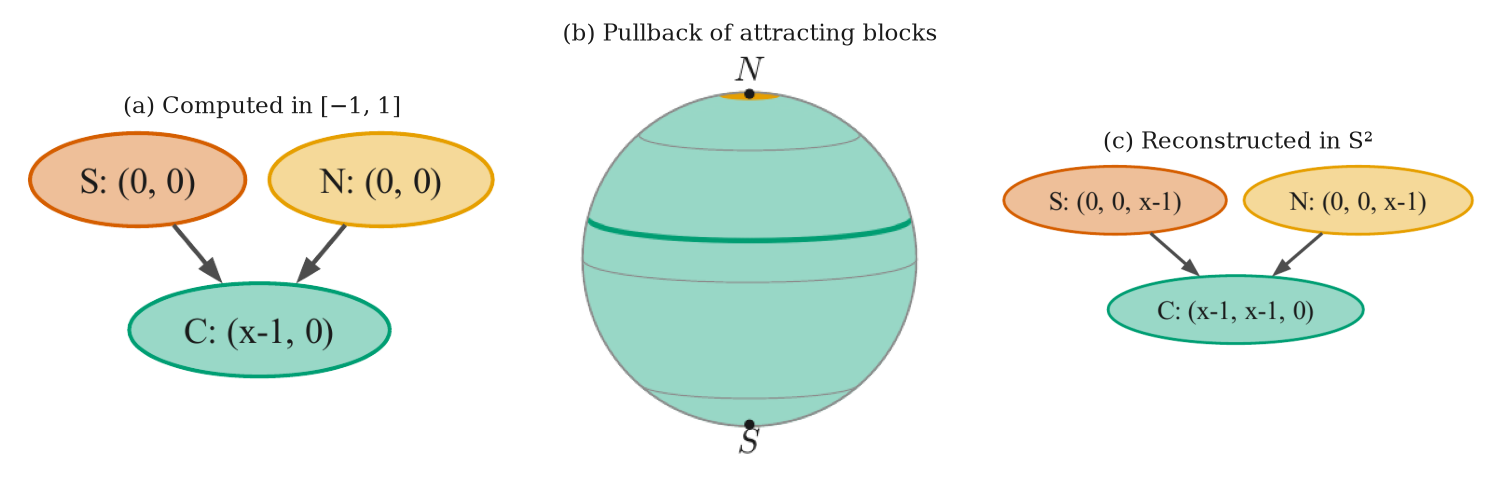

In [16]:
run.figure_coning()

## Interval cells and their sphere preimages

Each colored interval cell \([u_-,u_+]\) corresponds to the latent-sphere band \(\psi^{-1}(u_-)\leq\zeta\leq\psi^{-1}(u_+)\). The following plots place the Morse bands above their interval cells for each controller. This makes the relation between a one-dimensional computation and its sphere representation explicit. These plots show Morse components, not the full attracting regions.


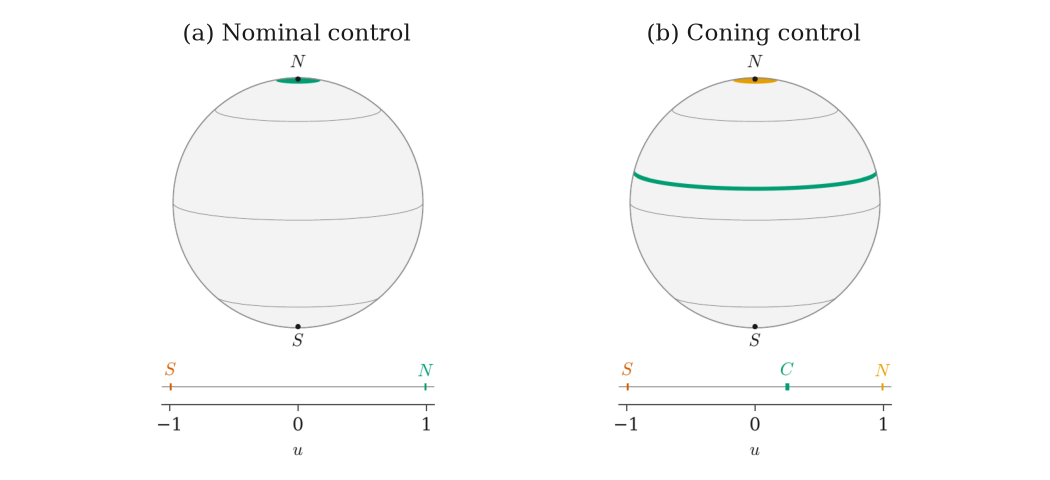

In [17]:
run.figure_appendix_spheres()

## Coning: reference and learned model

The left column shows the physical reference in height \(z\), and the right shows the grouped learned model in coordinate \(u\). From top to bottom, the rows show sphere Morse sets, interval cells, quotient indices, and reconstructed sphere indices. The sphere is physical \(X\) on the left and latent \(Z\) on the right.


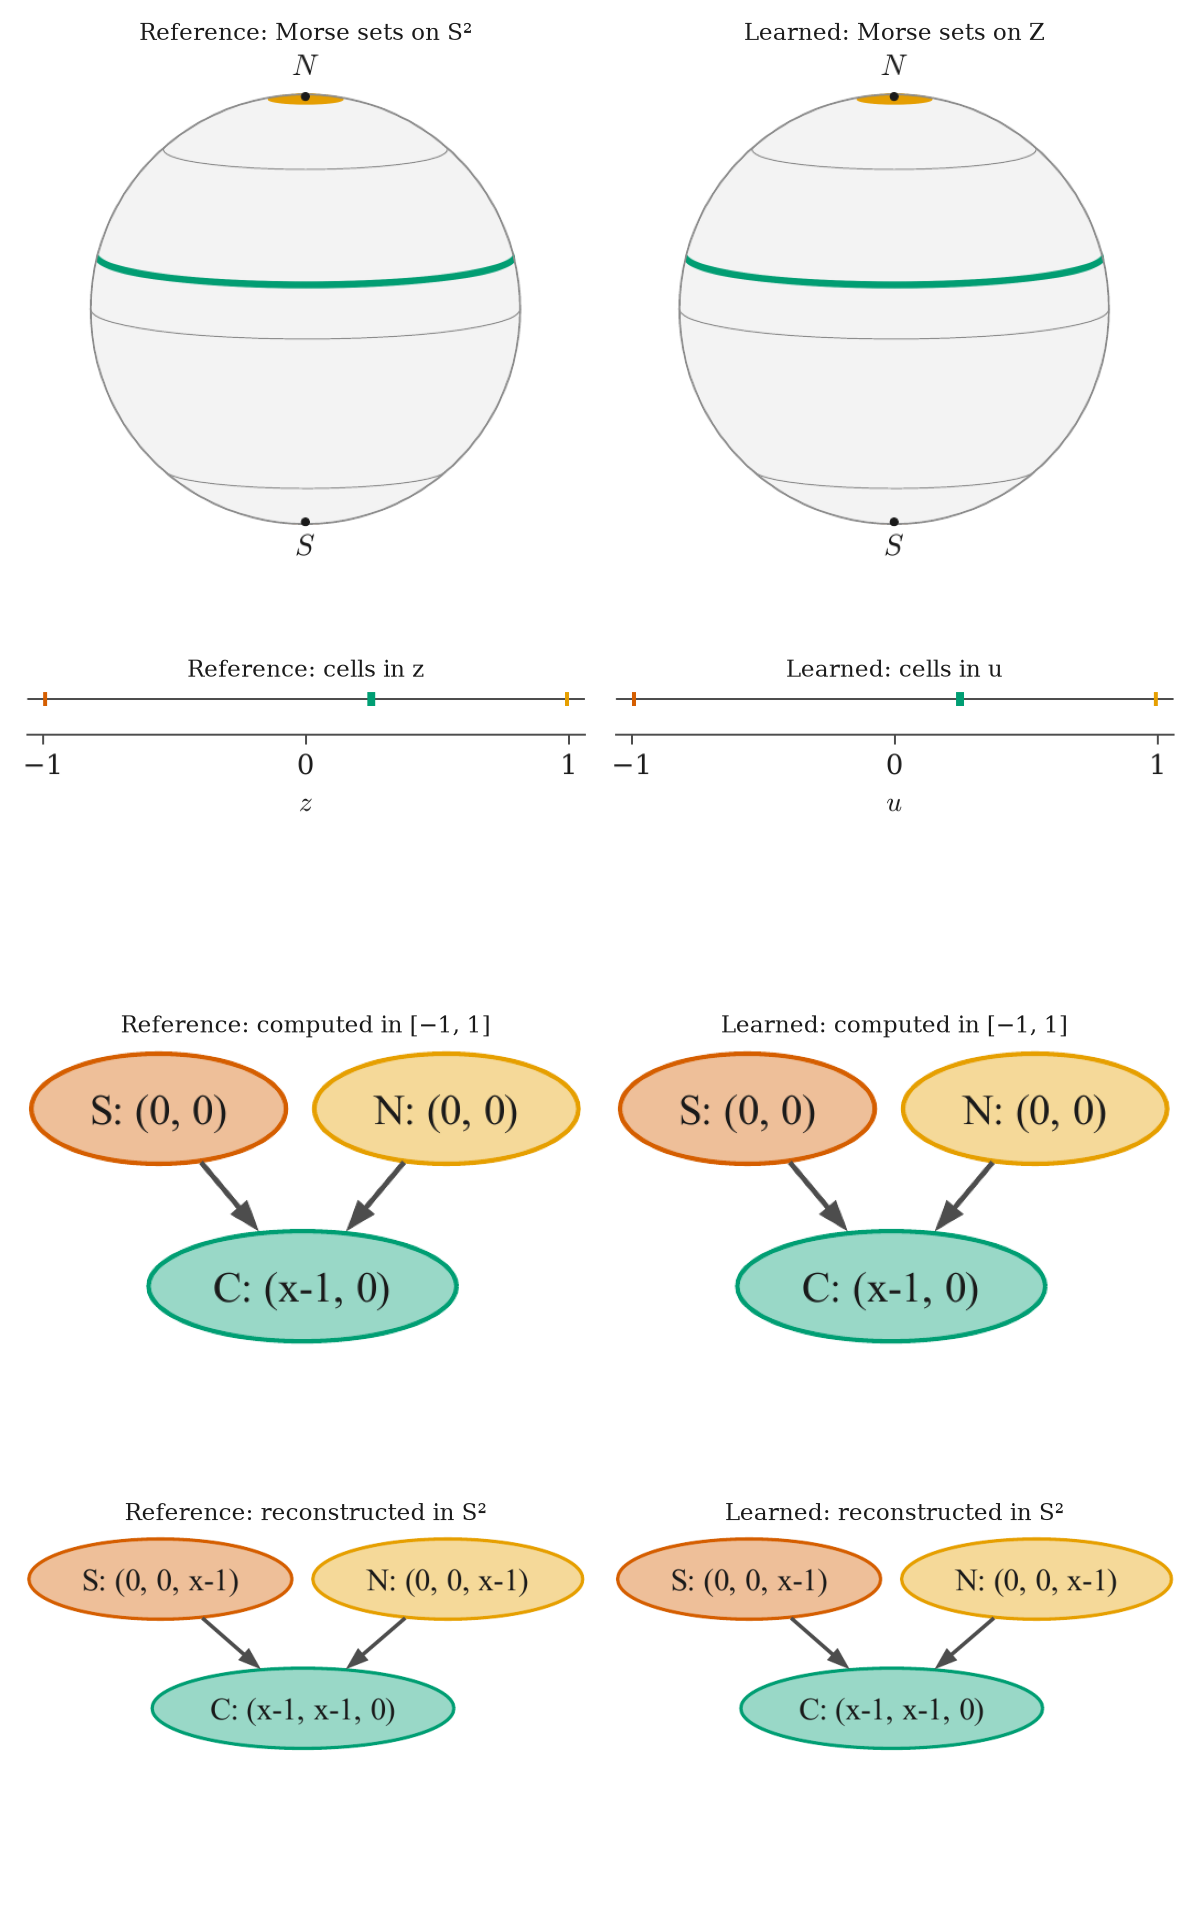

In [18]:
run.figure_appendix_comparison()

## Reproducibility check

The run saves graphs, regions, tolerances, residuals, indices, and diagnostics in `OUT/results.json`. Replay compares them with [`reference/results.json`](data/ex3_attitude_control/reference/results.json), requiring exact graph agreement and numerical agreement to relative tolerance \(10^{-6}\). A mismatch stops the replay. Train mode reports differences from the saved reference.


In [19]:
run.check()

Replay check passed: 5990 numbers and 12 Morse graphs agree with data/ex3_attitude_control/reference/results.json (graphs exactly, numbers to relative tolerance 1e-06).

## Results alongside the manuscript

The final table places the computed quantities beside the manuscript values recorded in the implementation. It is a comparison with those recorded values, not a check of the current LaTeX source. Execution times depend on the machine.

The control behaviors in this example are prescribed, and the encoder is supervised by the known thrust direction. The computation tests whether the learned model retains their distinction and connecting structure on \(\eta=0\). The sampled graph and residual checks provide numerical evidence within that scope.


In [20]:
run.summary()

statement,where,manuscript,computed,agrees
"Coning orbit: period and transverse Floquet multipliers in (q, η)",Section 5.3,period 2 log 2; exp(−15 log 2/8) and 1/16 three times,period 1.38629; 0.272627 and 0.0625 three times; 1 along C,yes
One-second axis RMS on held-out trajectories from η = 0,Section 5.3,below 0.002,"0.00101 (nominal), 0.00183 (coning)",yes
Nominal: reference and learned Morse graphs on 2^7 cells,Section 5.3,agree; order −e₃ → e₃; matching indices,"reference S → N: S (0, 0), N (x-1, 0); learned S → N: S (0, 0), N (x-1, 0)",yes
Coning: reference Morse graph in z,Section 5.3,−e₃ → C ← e₃,"S → C, N → C: S (0, 0), C (x-1, 0), N (0, 0)",yes
Coning: a fourth Morse set in the coordinate ψ,Section 5.3,reference and learned each have one; learned: one cell next to C with zero index,"reference in ψ: A = cell [0.234375, 0.25] (0, 0); learned: A = cell [0.25, 0.265625] (0, 0)",yes
"Coning: merged Morse set, index recomputed by CMGDB on the merged pair",Section 5.3,order −e₃ → C ← e₃ of the reference,"C = [0.234375, 0.265625] from 2 Morse sets, (x-1, 0); S → C, N → C",yes
Sample maxima of the residual modulo G of the tenth iterate (chordal metric),Section 5.3,0.015 for both gains,"0.014871 (nominal), 0.0148922 (coning)",yes
Estimated tolerances,Section 5.3,0.29 at e₃ (nominal) and 0.17 at the merged region (coning),"0.294831 at e₃, 0.172168 at the merged C",yes
Coning: attracting region of the minimal Morse set C of the raw graph,"Section 5, definition of 𝒜",𝒜 is defined for a minimal Morse set; Section 5.3 reports the merged region,"79 cells, tolerance 0.00180907 against residual 0.0148922 (fails)",not stated
Indices of the axis dynamics in S²,Section 5.3 and the supplement,"H₂ = F at a repelling pole, H₀ = F at the nominal sink, H₀ = H₁ = F at C","nominal: N (x-1, 0, 0), S (0, 0, x-1); coning: C (x-1, x-1, 0), S (0, 0, x-1), N (0, 0, x-1) (reference and learned)",yes


In [21]:
run.verification()

Wrote outputs/notebooks/ex3_attitude_control-replay-20261114-013128/verification.json: check passed, 15 statements, 14 panels as PDF and SVG.